In [1]:
import pandas as pd

df = pd.read_csv('IPLPlayerStat.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings,player_form,player_form_encoded
0,0,0,A Ashish Reddy,280,31,196,NaN,270,400,28,10.00,142.86,15.82,8.89,22.22,15.00,8,0,Poor,0
1,1,1,A Badoni,161,18,139,2.0,12,12,11,14.64,115.83,12.95,6.00,6.00,6.00,8,0,Average,1
2,2,2,A Chandila,4,0,7,11.0,234,245,12,0.33,57.14,0.00,6.28,22.27,21.27,2,0,Poor,0
3,3,3,A Chopra,53,7,75,0.0,0,0,6,8.83,70.67,9.33,0.00,0.00,0.00,2,0,Poor,0
4,4,4,A Choudhary,25,2,20,5.0,108,144,5,5.00,125.00,10.00,8.00,28.80,21.60,0,0,Poor,0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 605 entries, 0 to 604
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0.1         605 non-null    int64  
 1   Unnamed: 0           605 non-null    int64  
 2   player               605 non-null    object 
 3   runs                 605 non-null    int64  
 4   boundaries           605 non-null    int64  
 5   balls_faced          605 non-null    int64  
 6   wickets              598 non-null    float64
 7   balls_bowled         605 non-null    int64  
 8   runs_conceded        605 non-null    int64  
 9   matches              605 non-null    int64  
 10  batting_avg          605 non-null    float64
 11  batting_strike_rate  605 non-null    float64
 12  boundaries_percent   605 non-null    float64
 13  bowling_economy      605 non-null    float64
 14  bowling_avg          605 non-null    float64
 15  bowling_strike_rate  605 non-null    flo

In [3]:
# there are better ways , we have also seen them , but right now , just do it , im tired !!
df = df.dropna()

In [4]:
df.head()

,Unnamed: 0.1,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings,player_form,player_form_encoded
1,1,1,A Badoni,161,18,139,2.0,12,12,11,14.64,115.83,12.95,6.00,6.00,6.00,8,0,Average,1
2,2,2,A Chandila,4,0,7,11.0,234,245,12,0.33,57.14,0.00,6.28,22.27,21.27,2,0,Poor,0
3,3,3,A Chopra,53,7,75,0.0,0,0,6,8.83,70.67,9.33,0.00,0.00,0.00,2,0,Poor,0
4,4,4,A Choudhary,25,2,20,5.0,108,144,5,5.00,125.00,10.00,8.00,28.80,21.60,0,0,Poor,0
5,5,5,A Dananjaya,4,0,5,0.0,25,47,1,4.00,80.00,0.00,11.28,470000.00,250000.00,0,0,Poor,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 598 entries, 1 to 604
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0.1         598 non-null    int64  
 1   Unnamed: 0           598 non-null    int64  
 2   player               598 non-null    object 
 3   runs                 598 non-null    int64  
 4   boundaries           598 non-null    int64  
 5   balls_faced          598 non-null    int64  
 6   wickets              598 non-null    float64
 7   balls_bowled         598 non-null    int64  
 8   runs_conceded        598 non-null    int64  
 9   matches              598 non-null    int64  
 10  batting_avg          598 non-null    float64
 11  batting_strike_rate  598 non-null    float64
 12  boundaries_percent   598 non-null    float64
 13  bowling_economy      598 non-null    float64
 14  bowling_avg          598 non-null    float64
 15  bowling_strike_rate  598 non-null    float64


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

<Axes: >

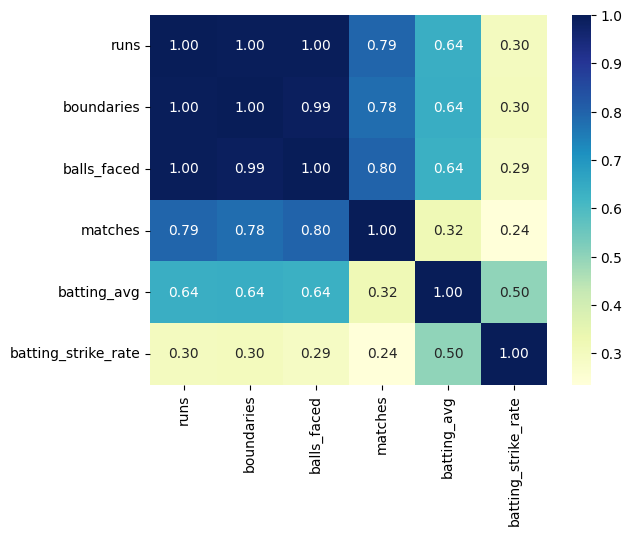

In [7]:
cols = ['runs' , 'boundaries' , 'balls_faced' , 'matches' , 'batting_avg' , 'batting_strike_rate' ]
correlation = df[cols].corr()

sns.heatmap(
    correlation ,
    annot = True ,
    fmt = ".2f" ,
    cmap = 'YlGnBu'
)

as we can see , [ runs , boundaries and balls_faced ] are correlating more with each other , best suited features for regression

regression on balls faced and runs

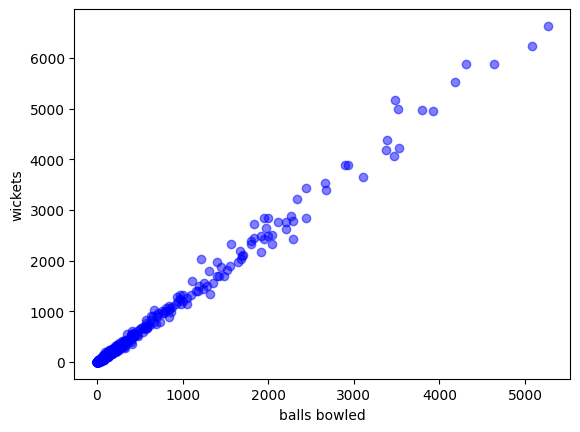

In [8]:
# linear regression on balls bowled and wickets

x = df[['balls_faced']]
y = df[['runs']]
plt.scatter( x , y , color = 'blue' , alpha = 0.5)
plt.xlabel('balls bowled')
plt.ylabel('wickets')
plt.show()

In [9]:
x_train , x_test , y_train , y_test = train_test_split(x,y, test_size = 0.2 , random_state = 42)
model = LinearRegression()
model.fit(x_train , y_train)

print("intercept : " , round(model.intercept_.item() , 2))
print("slop : " , round(model.coef_[0].item() , 4))

print(f"the equation will be y = {round(model.coef_[0].item() , 4)}x + {round(model.intercept_.item() , 2)}" )

intercept :  -14.48
slop :  1.2742
the equation will be y = 1.2742x + -14.48


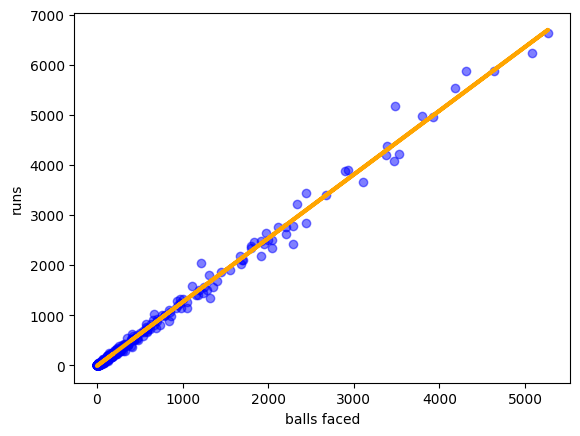

In [10]:
plt.scatter( x_train , y_train , color = 'blue' , alpha = 0.5)
plt.plot(x_train , model.predict(x_train) , color = 'orange' , linewidth = 3 , label = 'best fit')
plt.xlabel('balls faced')
plt.ylabel('runs')
plt.show()

In [11]:
# evaluation
import numpy as np
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score
mae = mean_absolute_error(y_test , model.predict(x_test))
mse = mean_squared_error(y_test , model.predict(x_test))
r2 = r2_score(y_test , model.predict(x_test))

print(f"mean absolute error : {mae}")
print(f"mean squared error : {mse}")
print(f"R2 : {r2}")


mean absolute error : 43.3402038029117
mean squared error : 8535.27606779822
R2 : 0.9876230660208348


regression on boundaries and runs

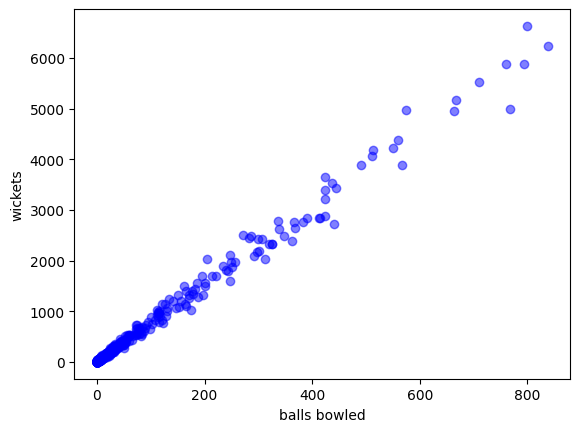

In [12]:
x = df[['boundaries']]
y = df[['runs']]
plt.scatter( x , y , color = 'blue' , alpha = 0.5)
plt.xlabel('balls bowled')
plt.ylabel('wickets')
plt.show()

In [13]:
x_train , x_test , y_train , y_test = train_test_split(x,y, test_size = 0.2 , random_state = 42)
model = LinearRegression()
model.fit(x_train , y_train)

print("intercept : " , round(model.intercept_.item() , 2))
print("slop : " , round(model.coef_[0].item() , 4))

print(f"the equation will be y = {round(model.coef_[0].item() , 4)}x + {round(model.intercept_.item() , 2)}" )

intercept :  7.9
slop :  7.6984
the equation will be y = 7.6984x + 7.9


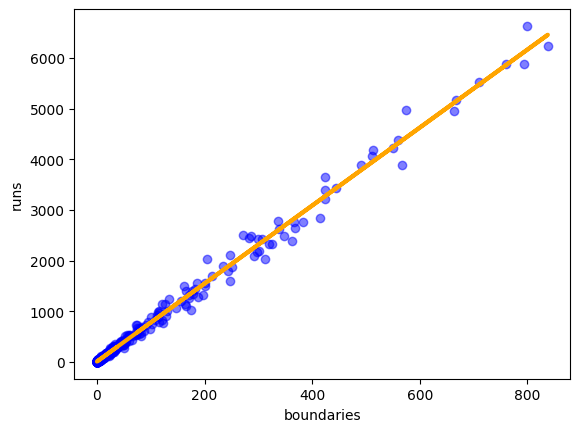

In [14]:
plt.scatter( x_train , y_train , color = 'blue' , alpha = 0.5)
plt.plot(x_train , model.predict(x_train) , color = 'orange' , linewidth = 3 , label = 'best fit')
plt.xlabel('boundaries')
plt.ylabel('runs')
plt.show()

In [15]:
mae = mean_absolute_error(y_test , model.predict(x_test))
mse = mean_squared_error(y_test , model.predict(x_test))
r2 = r2_score(y_test , model.predict(x_test))

print(f"mean absolute error : {mae}")
print(f"mean squared error : {mse}")
print(f"R2 : {r2}")

mean absolute error : 45.3507341255595
mean squared error : 15277.21223310576
R2 : 0.9778466395588279


lets combine these features and do a multiple regression

In [16]:
features = ['balls_faced' , 'boundaries']
x = df[features]
y = df['runs']

x_train , x_test , y_train , y_test = train_test_split(x,y, test_size = 0.2 , random_state = 42)
model = LinearRegression()
model.fit(x_train , y_train)

print("intercept : " , round(model.intercept_.item() , 2))
print("slope : " , round(model.coef_[0].item() , 4))

print(f"the equation will be y = {round(model.coef_[0].item() , 4)}x + {round(model.intercept_.item() , 2)}" )

intercept :  -5.86
slope :  0.6749
the equation will be y = 0.6749x + -5.86


slope of balls_faced and boundaries ( individually )

In [17]:
for feature , coefficient in zip(features , model.coef_):
  print(f"{feature} : {coefficient}")

balls_faced : 0.6749152852201556
boundaries : 3.651853526893505


In [18]:
mae = mean_absolute_error(y_test , model.predict(x_test))
mse = mean_squared_error(y_test , model.predict(x_test))
r2 = r2_score(y_test , model.predict(x_test))

print(f"mean absolute error : {mae}")
print(f"mean squared error : {mse}")
print(f"R2 : {r2}")

mean absolute error : 19.5628393526432
mean squared error : 1436.2776566953607
R2 : 0.9979172655235211


mean absolute error was 43 for balls_faced and 45 for boundaries , but combining them , it has come to 19

In [ ]:
import plotly.graph_objects as go

intercept = -5.86

coeff = {
    "balls_faced" : 0.6749 ,
    "boundaries" : 3.6518
}

def predict(balls_faced , boundaries) :
  return (
      intercept + coeff['balls_faced'] * balls_faced + coeff['boundaries'] * boundaries
  )

x_feature = 'balls_faced'
y_feature = 'boundaries'

x = np.linspace(df[x_feature].min() , df[x_feature].max())
y = np.linspace(df[y_feature].min() , df[y_feature].max())

x_plane , y_plane = np.meshgrid(x,y)

z_plane = predict(x_plane , y_plane)

df['predicted'] = predict(
    df['balls_faced'] ,
    df['boundaries']
)

fig = go.Figure()

fig.add_trace(go.Surface(
    x = x_plane ,
    y = y_plane ,
    z = z_plane ,
    colorscale = 'Viridis' ,
    opacity = 0.5 ,
    name = 'regression surface' ,
    showscale = True
))

fig.add_trace(go.Scatter3d(
    x = df[x_feature],
    y = df[y_feature] ,
    z = df['predicted'],
    mode = 'markers',
    marker = dict(
        size = 5 ,
        color = 'red'
    ) ,
    text = df['player'] ,
    hovertemplate="<b> %{text} </b><br>" +
                  f"{x_feature.replace('_' , ' ').title()} : %{{x:2f}}<br>" +
                  f"{y_feature.replace('_' , ' ').title()} : %{{y}}<br>" +
                  "prediction : %{z:.2f} <extra></extra>",
    name = 'players'

))

fig.update_layout(
    title = 'multiple linear regression surface' ,
    scene = dict(
        xaxis_title = x_feature.replace('_',' ').title(),
        yaxis_title = y_feature.replace('_',' ').title(),
        zaxis_title = 'predicted value'
    ) ,
    width = 1000 ,
    height = 750
)

fig.show()

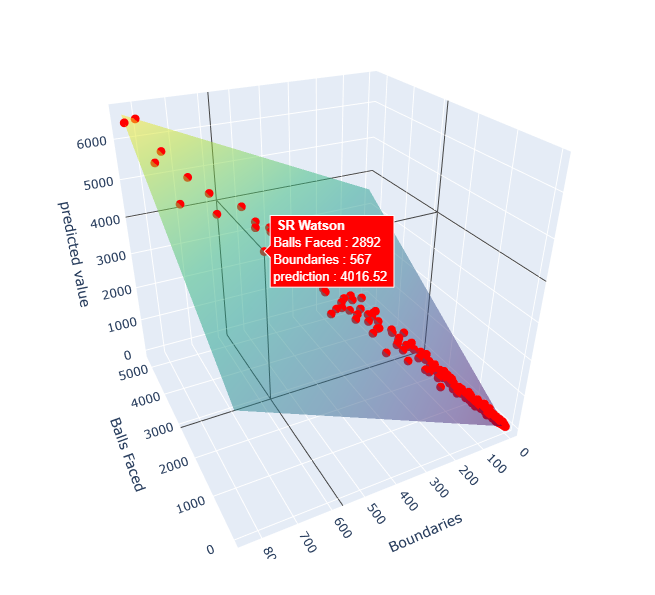

3D plane graph for multi linear regression